# ML Assignment 2 – Classification on the UCI Adult (Census Income) dataset

End-to-end workflow: dataset analysis → preprocessing → 5 classifiers → 6 evaluation metrics → comparison & visualisation.

All reusable logic lives in `pipeline_utils.py`, `models.py` and `train_models.py` in this folder, so the notebook and the command-line script produce identical results.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display, Markdown

import pipeline_utils as pu
import train_models

pd.set_option("display.width", 140)
print("Random seed:", pu.SEED)

Random seed: 2026


## Step 1 – Dataset

Load both UCI files (`adult.data` + `adult.test`) → 48,842 instances, 14 features + 1 target (`income`). UCI marks missing values with `?`; they are read as NaN.

In [2]:
raw = pu.load_raw_data()
print("Shape:", raw.shape)
raw.head()

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
feature_types = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "type": ["Target" if c == pu.TARGET else ("Numeric" if c in pu.NUMERIC_FEATURES else "Categorical") for c in raw.columns],
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
})
feature_types

,dtype,type,n_unique,missing,missing_%
age,int64,Numeric,74,0,0.00
workclass,object,Categorical,8,2799,5.73
fnlwgt,int64,Numeric,28523,0,0.00
education,object,Categorical,16,0,0.00
education_num,int64,Numeric,16,0,0.00
marital_status,object,Categorical,7,0,0.00
occupation,object,Categorical,14,2809,5.75
relationship,object,Categorical,6,0,0.00
race,object,Categorical,5,0,0.00
sex,object,Categorical,2,0,0.00


        count  percent
income                
<=50K   37155    76.07
>50K    11687    23.93
Imbalance ratio (majority:minority) = 3.18 : 1


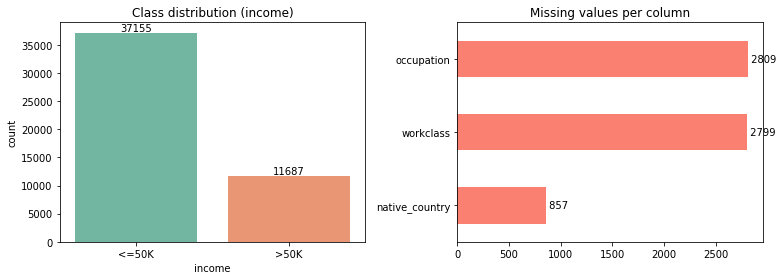

In [4]:
counts = raw[pu.TARGET].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(raw) * 100).round(2)}))
print(f"Imbalance ratio (majority:minority) = {counts.iloc[0] / counts.iloc[1]:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=raw[pu.TARGET], ax=axes[0], palette="Set2", hue=raw[pu.TARGET], legend=False)
axes[0].set_title("Class distribution (income)")
for c in axes[0].containers:
    axes[0].bar_label(c)
miss = raw.isna().sum()
miss = miss[miss > 0].sort_values()
miss.plot.barh(ax=axes[1], color="salmon")
axes[1].set_title("Missing values per column")
for i, v in enumerate(miss):
    axes[1].text(v, i, f" {v}", va="center")
plt.tight_layout()
pu.RESULTS_DIR.mkdir(exist_ok=True)
plt.savefig(pu.RESULTS_DIR / "class_distribution_and_missing.png", dpi=150)
plt.show()

In [5]:
raw[pu.NUMERIC_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0


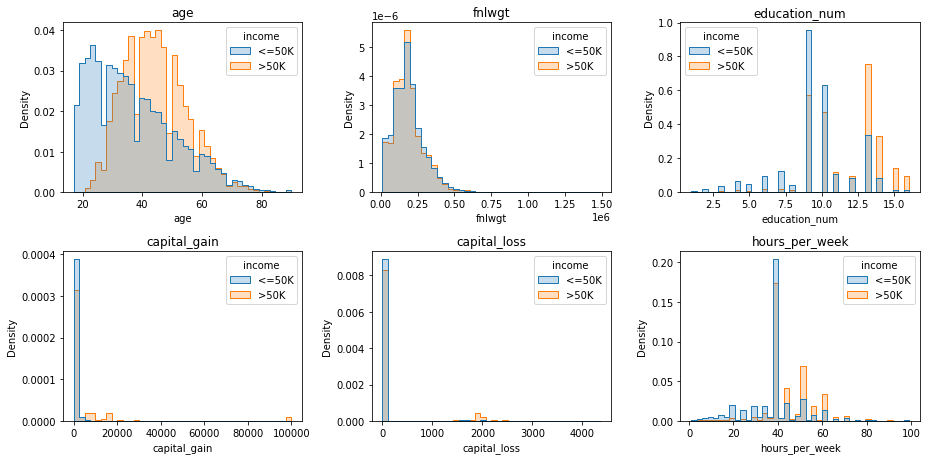

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), pu.NUMERIC_FEATURES):
    sns.histplot(data=raw, x=col, hue=pu.TARGET, bins=40, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(pu.RESULTS_DIR / "numeric_distributions.png", dpi=150)
plt.show()

## Step 2 – Preprocessing

1. **Duplicates** – exact duplicate rows are dropped.
2. **Redundant column** – `education` is dropped (1-to-1 text form of `education_num`), leaving 13 features.
3. **Stratified 80:20 split** with a fixed seed (`SEED = 2026`).
4. Inside every model `Pipeline` (so it is **fitted on training data only**):
   * numeric → median imputation → `StandardScaler` (only for scale-sensitive models: LR, kNN, NB)
   * categorical → most-frequent imputation (handles the `?` values) → `OneHotEncoder` (rare levels < 10 grouped as *infrequent*, unseen levels ignored)

In [7]:
clean, report = pu.clean_data(raw)
print(report)
print("Education vs education_num mapping is 1-to-1:",
      raw.groupby("education")["education_num"].nunique().max() == 1)
X_train, X_test, y_train, y_test = pu.split_data(clean)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(pd.DataFrame({"train %>50K": [y_train.mean() * 100], "test %>50K": [y_test.mean() * 100]}).round(2))

{'rows_before': 48842, 'duplicates': 52, 'rows_after': 48790}
Education vs education_num mapping is 1-to-1: True
Train: (39032, 13)  Test: (9758, 13)
   train %>50K  test %>50K
0        23.94       23.94


In [8]:
prep = pu.build_preprocessor(scale=True).fit(X_train)   # fitted on train only
print("Encoded feature matrix:", prep.transform(X_train).shape)
print("Missing values after preprocessing:", np.isnan(prep.transform(X_test)).sum())

Encoded feature matrix: (39032, 89)
Missing values after preprocessing: 0


## Step 3 – Models and evaluation

`train_models.main()` performs, for each of the 5 models, a small grid search (5-fold stratified CV on the training set, scoring = ROC-AUC), refits the best pipeline on the full training set, evaluates it on the held-out 20% test set, and saves it to `model/saved_models/*.pkl`. It also writes `test_data.csv`, `results/metrics.csv` and all plots.

In [9]:
results, configs = train_models.main()

Cleaning: {'rows_before': 48842, 'duplicates': 52, 'rows_after': 48790}
Train: (39032, 13), Test: (9758, 13), positive rate train=0.2394 test=0.2394


Logistic Regression        Accuracy=0.8523 AUC=0.9078 Precision=0.7379 Recall=0.5942 F1=0.6583 MCC=0.5709  best={'C': 0.1}  (10s)


Decision Tree              Accuracy=0.8604 AUC=0.9100 Precision=0.7899 Recall=0.5681 F1=0.6609 MCC=0.5883  best={'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 60}  (34s)


kNN                        Accuracy=0.8498 AUC=0.9014 Precision=0.7151 Recall=0.6190 F1=0.6636 MCC=0.5700  best={'n_neighbors': 31, 'weights': 'uniform'}  (43s)


Naive Bayes                Accuracy=0.7897 AUC=0.8862 Precision=0.5405 Recall=0.8104 F1=0.6485 MCC=0.5280  best={'var_smoothing': 0.1}  (5s)


Random Forest (Ensemble)   Accuracy=0.8675 AUC=0.9222 Precision=0.7945 Recall=0.6023 F1=0.6852 MCC=0.6125  best={'max_depth': 14, 'max_features': 0.3, 'min_samples_leaf': 2}  (276s)



                          Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                        
Logistic Regression         0.8523  0.9078     0.7379  0.5942  0.6583  0.5709
Decision Tree               0.8604  0.9100     0.7899  0.5681  0.6609  0.5883
kNN                         0.8498  0.9014     0.7151  0.6190  0.6636  0.5700
Naive Bayes                 0.7897  0.8862     0.5405  0.8104  0.6485  0.5280
Random Forest (Ensemble)    0.8675  0.9222     0.7945  0.6023  0.6852  0.6125


In [10]:
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8523,0.9078,0.7379,0.5942,0.6583,0.5709
Decision Tree,0.8604,0.9100,0.7899,0.5681,0.6609,0.5883
kNN,0.8498,0.9014,0.7151,0.6190,0.6636,0.5700
Naive Bayes,0.7897,0.8862,0.5405,0.8104,0.6485,0.5280
Random Forest (Ensemble),0.8675,0.9222,0.7945,0.6023,0.6852,0.6125


In [11]:
pd.DataFrame({k: {**v["best_params"], "cv_roc_auc": v["cv_roc_auc"]} for k, v in configs.items()}).T

,C,cv_roc_auc,criterion,max_depth,min_samples_leaf,n_neighbors,weights,var_smoothing,max_features
Logistic Regression,0.1,0.9041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Decision Tree,NaN,0.9044,gini,10,60,NaN,NaN,NaN,NaN
kNN,NaN,0.8965,NaN,NaN,NaN,31,uniform,NaN,NaN
Naive Bayes,NaN,0.8837,NaN,NaN,NaN,NaN,NaN,0.1,NaN
Random Forest (Ensemble),NaN,0.9184,NaN,14.0,2.0,NaN,NaN,NaN,0.3


## Visualisation of all metrics

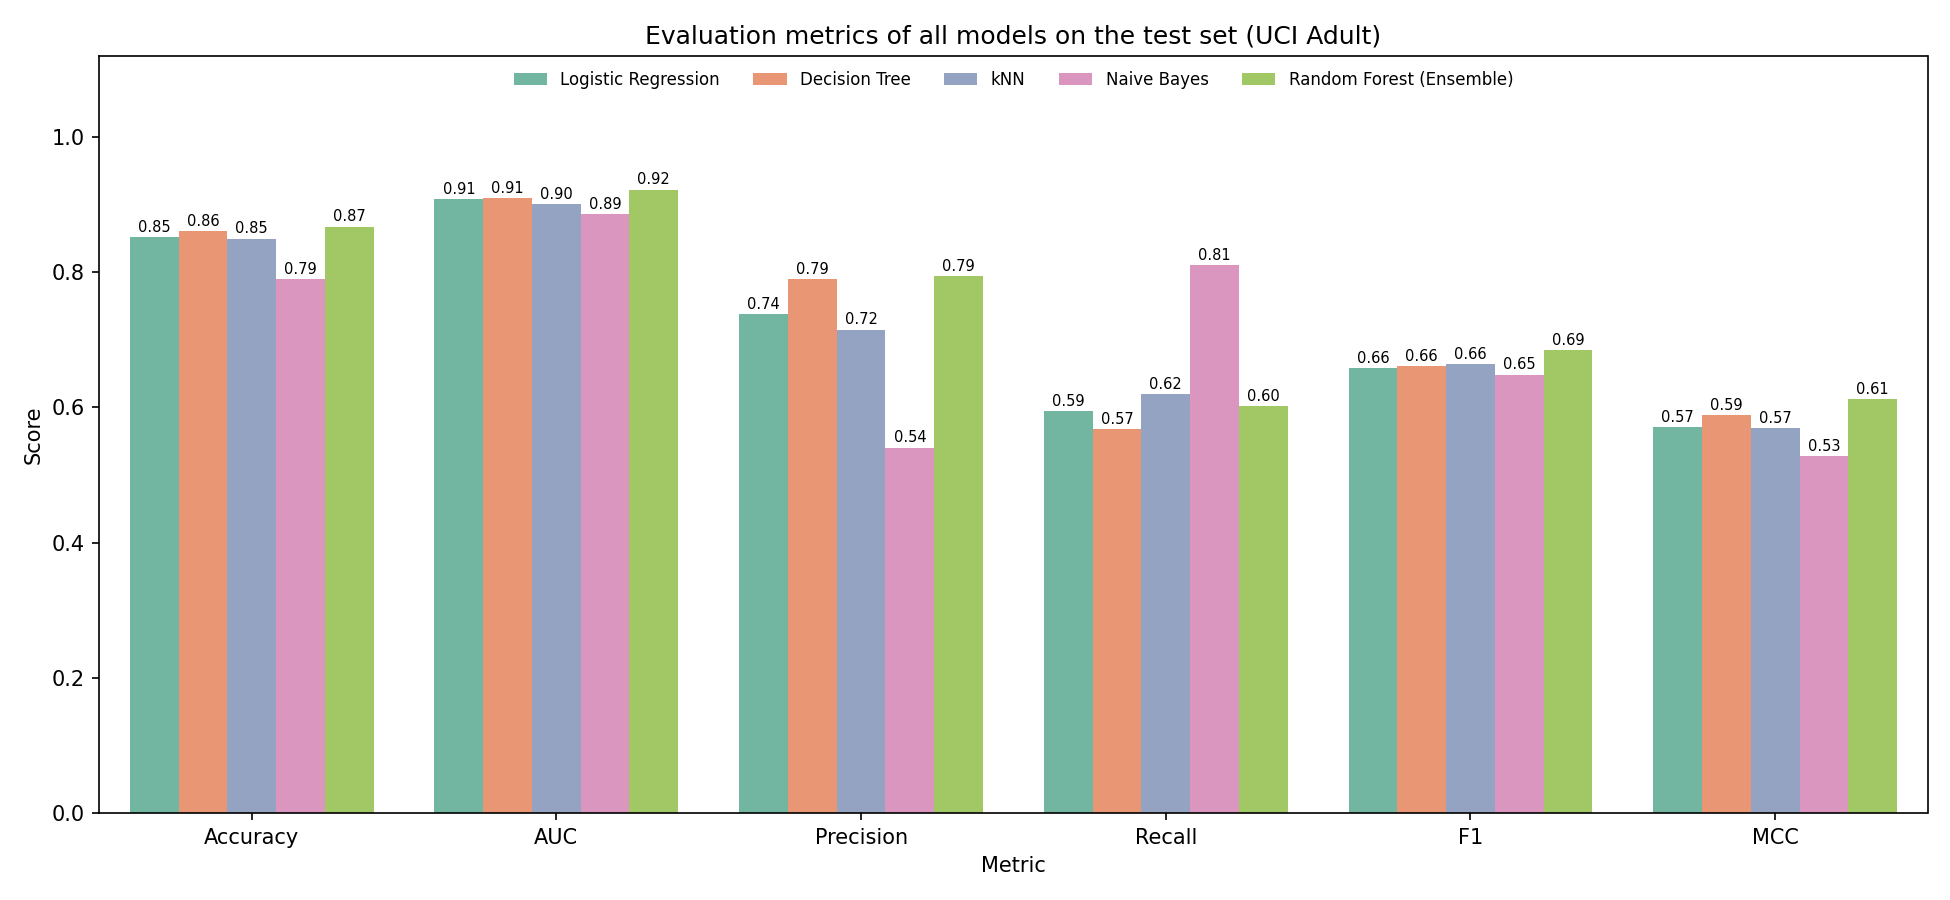

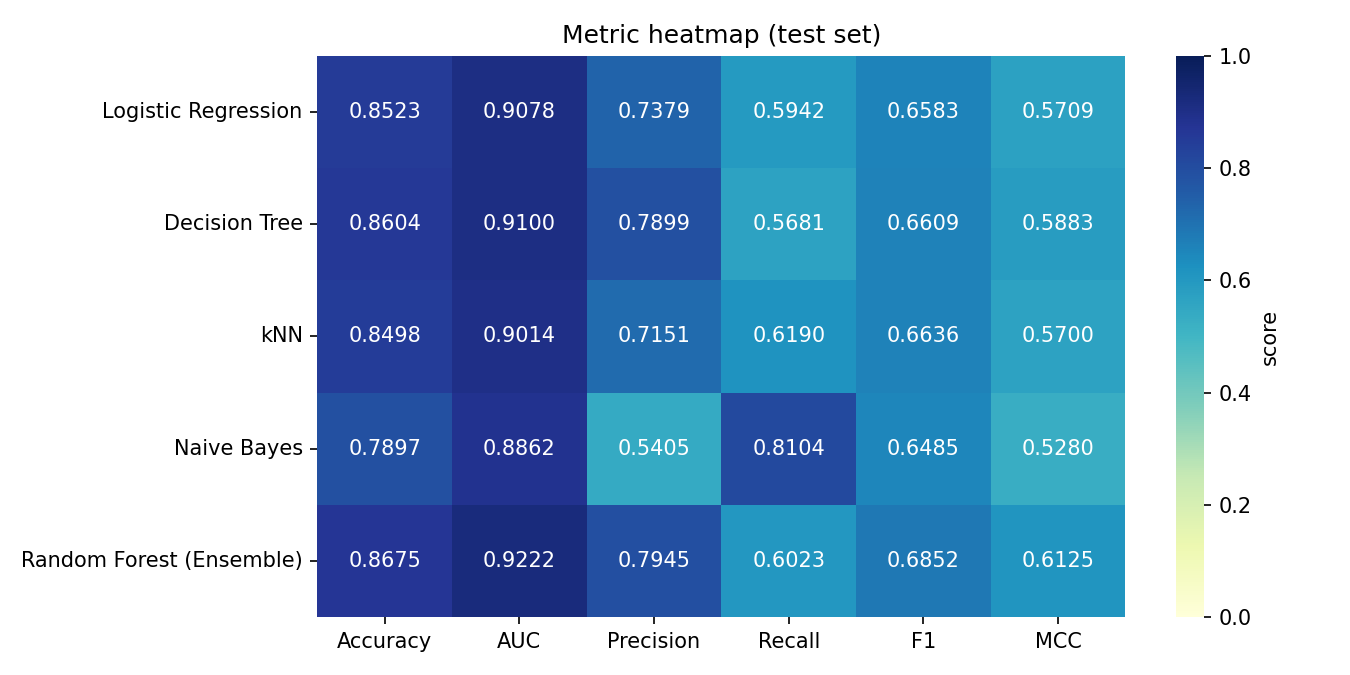

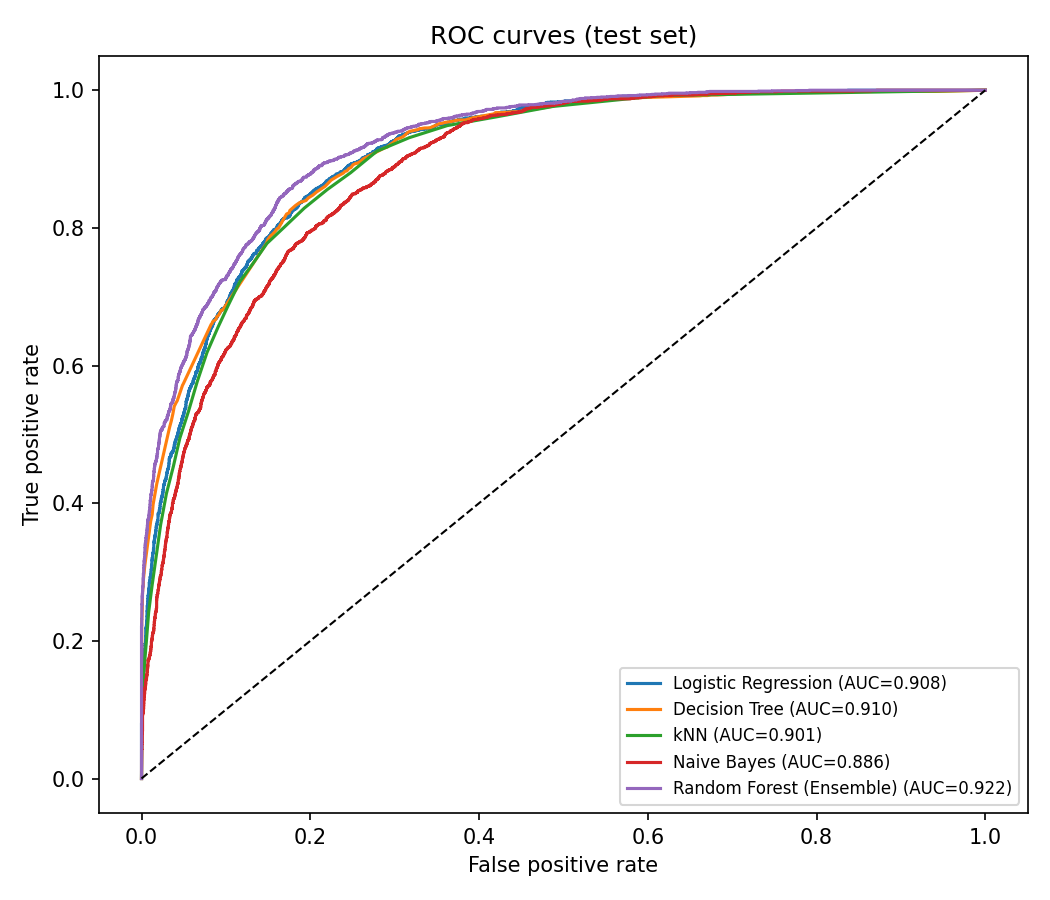

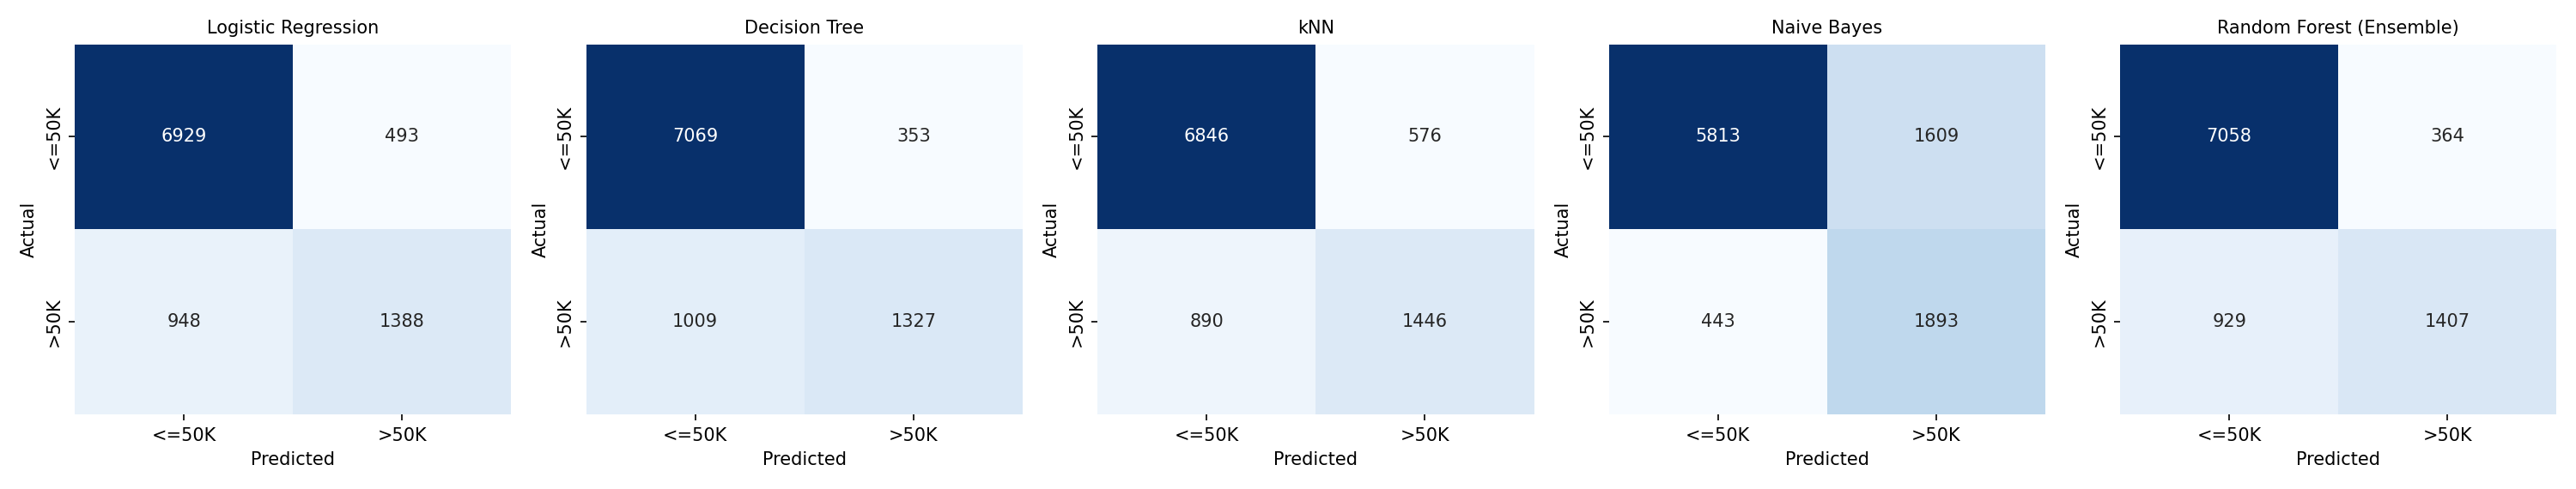

In [12]:
for f in ["metrics_comparison.png", "metrics_heatmap.png", "roc_curves.png", "confusion_matrices.png"]:
    display(Image(filename=str(pu.RESULTS_DIR / f)))

In [13]:
best = results.idxmax()
print("Best model per metric:")
print(best.to_string())

Best model per metric:
Accuracy     Random Forest (Ensemble)
AUC          Random Forest (Ensemble)
Precision    Random Forest (Ensemble)
Recall                    Naive Bayes
F1           Random Forest (Ensemble)
MCC          Random Forest (Ensemble)


## Reproducibility check – reload saved models and score `test_data.csv`

In [14]:
import predict
predict.main()

                            Accuracy     AUC  Precision  Recall      F1     MCC
Model file                                                                     
decision_tree.pkl             0.8604  0.9100     0.7899  0.5681  0.6609  0.5883
knn.pkl                       0.8498  0.9014     0.7151  0.6190  0.6636  0.5700
logistic_regression.pkl       0.8523  0.9078     0.7379  0.5942  0.6583  0.5709
naive_bayes.pkl               0.7897  0.8862     0.5405  0.8104  0.6485  0.5280
random_forest_ensemble.pkl    0.8675  0.9222     0.7945  0.6023  0.6852  0.6125
